In [16]:
#Importación de librerías
#numpy fundamental para gestión de arrays N-dimensionales
import numpy as np
#scipy para cálculo numérico, álgebra lineal, etc. Ambos básicos para computación científica
import scipy as sc
#matplotlib Gráficas
import matplotlib.pyplot as plt
#https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_circles.html Permite dibujar un par de círculos
from sklearn import datasets

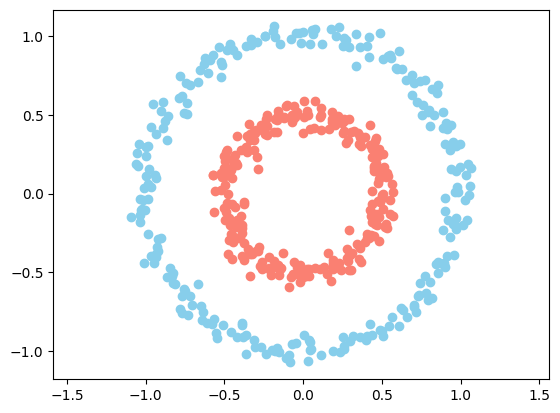

In [17]:
# CREAR EL DATASET

n = 500
p = 2

X, Y = datasets.make_circles(n_samples=n, factor=0.5, noise=0.05)

Y = Y[:, np.newaxis]

plt.scatter(X[Y[:, 0] == 0, 0], X[Y[:, 0] == 0, 1], c="skyblue")
plt.scatter(X[Y[:, 0] == 1, 0], X[Y[:, 0] == 1, 1], c="salmon")
plt.axis("equal")
plt.show()

In [18]:
# CLASE DE LA CAPA DE LA RED

class neural_layer():

  def __init__(self, n_conn, n_neur, act_f):
    self.act_f = act_f

    self.b = np.random.rand(1, n_neur)      * 2 - 1
    self.W = np.random.rand(n_conn, n_neur) * 2 - 1

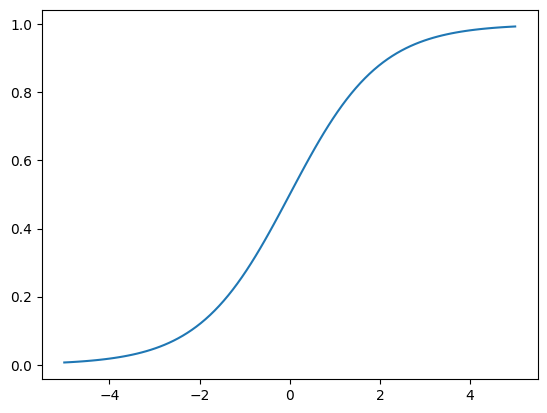

In [19]:
# FUNCIONES DE ACTIVACIÓN Y SUS DERIVADAS

# Cada función es una tupla: (Función, Derivada)

# Sigmoide
sigm = (lambda x: 1 / (1 + np.e ** (-x)),
        lambda x: x * (1 - x))

# ReLU (con su derivada definida)
relu = (lambda x: np.maximum(0, x),
        lambda x: np.where(x > 0, 1, 0))

# Tangente Hiperbólica (tanh)
tanh = (lambda x: np.tanh(x),
        lambda x: 1 - np.tanh(x)**2)

# Diccionario para traducir nombres en formato String a las tuplas de funciones
functions_dict = {
    'sigm': sigm,
    'relu': relu,
    'tanh': tanh
}

_x = np.linspace(-5, 5, 100)
plt.plot(_x, sigm[0](_x))
#plt.plot(_x, sigm[1](_x)) #Para visualizar la derivada

In [20]:
# CREAMOS LA RED NEURONAL

# CREAMOS LA RED NEURONAL CON ARRAYS DE TOPOLOGIA Y ARRAY DE FUNCIONES DE ACTIVACION
def create_neuron_network(topology, act_functions):
  """
  Crea la arquitectura de la red neuronal recibiendo:
  - topology: array/lista con el número de neuronas por capa.
  - act_functions: array/lista con las funciones de activación para cada capa.
  """
  neuron_network = []

  for l in range(len(topology) - 1):
    act_f = act_functions[l]

    # Si la función se pasa como texto (ej: 'tanh'), se busca en el diccionario
    if isinstance(act_f, str):
      act_f = functions_dict[act_f]

    neuron_network.append(neural_layer(topology[l], topology[l+1], act_f))

  return neuron_network

In [22]:
# FUNCION DE ENTRENAMIENTO
topology = [p, 4, 8, 1] # --> lista_de_capas

# Capa 0 (Entrada): 2 neuronas (las coordenadas X e Y de los puntos del gráfico).
# Capa 1 (Oculta): 4 neuronas.
# Capa 2 (Oculta): 8 neuronas.
# Capa 3 (Salida): 1 neurona (la predicción final: si el punto es azul o)
l2_cost = (lambda Yp, Yr: np.mean((Yp - Yr) ** 2),
           lambda Yp, Yr: (Yp - Yr))

def train(neural_net, X, Y, l2_cost, lr=0.05, train=True):
  out = [(None, X)]

  # FORWARD PASS (Propagación hacia adelante)
  for l, layer in enumerate(neural_net):
    z = out[-1][1] @ neural_net[l].W + neural_net[l].b
    a = neural_net[l].act_f[0](z)
    out.append((z, a))

  if train:
    # BACKWARD PASS (Retropropagación del error)
    deltas = []

    for l in reversed(range(0, len(neural_net))):
      z = out[l+1][0]
      a = out[l+1][1]

      if l == len(neural_net) - 1:
        # Error en la última capa
        deltas.insert(0, l2_cost[1](a, Y) * neural_net[l].act_f[1](a))
      else:
        # Error propagado en las capas ocultas
        deltas.insert(0, deltas[0] @ _W.T * neural_net[l].act_f[1](a))

      _W = neural_net[l].W

      # GRADIENT DESCENT (Ajuste de pesos y sesgos)
      neural_net[l].b = neural_net[l].b - np.mean(deltas[0], axis=0, keepdims=True) * lr
      neural_net[l].W = neural_net[l].W - out[l][1].T @ deltas[0] * lr

  return out[-1][1]




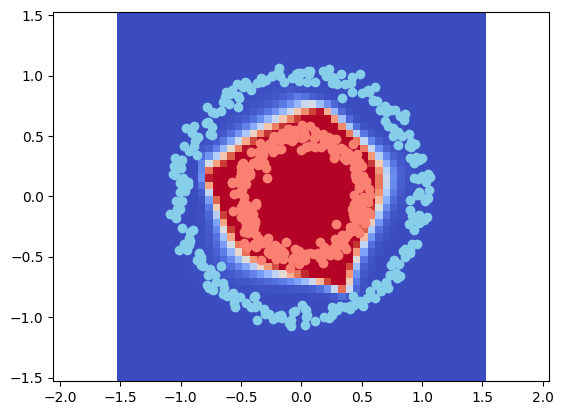

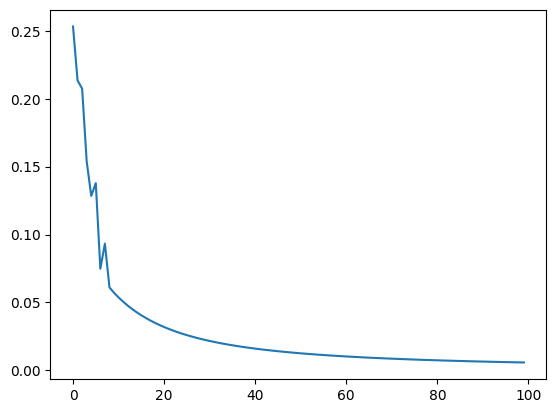

In [23]:
# VISUALIZACIÓN Y TEST

# Definición de la topología: Capa entrada (2), Oculta 1 (8), Oculta 2 (4), Salida (1)
topology = [p, 8, 4, 1]

# PASAMOS UN ARRAY CON UNA FUNCIÓN DE ACTIVACIÓN POR CADA CONEXIÓN ENTRE CAPAS
act_functions = [tanh, relu, sigm]

neural_n = create_neuron_network(topology, act_functions)

loss = []

for i in range(2500):
  # Entrenamos a la red
  pY = train(neural_n, X, Y, l2_cost, lr=0.05)

  if i % 25 == 0:
    loss.append(l2_cost[0](pY, Y))

    res = 50
    _x0 = np.linspace(-1.5, 1.5, res)
    _x1 = np.linspace(-1.5, 1.5, res)
    _Y = np.zeros((res, res))

    for i0, x0 in enumerate(_x0):
      for i1, x1 in enumerate(_x1):
        _Y[i0, i1] = train(neural_n, np.array([[x0, x1]]), Y, l2_cost, train=False)[0][0]

    plt.pcolormesh(_x0, _x1, _Y, cmap="coolwarm")
    plt.axis("equal")

    plt.scatter(X[Y[:,0] == 0, 0], X[Y[:,0] == 0, 1], c="skyblue")
    plt.scatter(X[Y[:,0] == 1, 0], X[Y[:,0] == 1, 1], c="salmon")

    clear_output(wait=True)
    plt.show()
    plt.plot(range(len(loss)), loss)
    plt.show()